# 16 — Capital Allocation & Position Sizing

Notebook này phân bổ vốn chi tiết theo tiêu chuẩn Kelly và quản trị NAV.

In [2]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [3]:
# Cell: Import Capital Modules
import importlib
import inspect
import numpy as np
import pandas as pd

import src.capital.management as capital_management
import src.reporting.chart_factory as chart_factory
from src.data.loaders import read_parquet

capital_management = importlib.reload(capital_management)
chart_factory = importlib.reload(chart_factory)

build_capital_plan = capital_management.build_capital_plan
align_capital_plan_to_target_weights = capital_management.align_capital_plan_to_target_weights
capital_plan_chart = chart_factory.capital_plan_chart
weight_comparison_chart = chart_factory.weight_comparison_chart


In [4]:
# Cell: Load Capital Inputs
import os
import pandas as pd

trade_cards = read_parquet("data/signals/breakout_20d_trade_cards.parquet")
eligibility = read_parquet("data/signals/breakout_20d_setup_eligibility.parquet")
volatility_df = read_parquet("data/processed/stock_features.parquet")
trade_cards["date"] = pd.to_datetime(trade_cards["date"])
volatility_df["date"] = pd.to_datetime(volatility_df["date"])
latest_vol = volatility_df.sort_values(["symbol", "date"]).groupby("symbol").tail(1)

capital_candidates = trade_cards.merge(
    latest_vol[["symbol", "atr_pct_14"]],
    on="symbol",
    how="left",
)
capital_candidates = capital_candidates.merge(
    eligibility[["symbol", "win_rate", "avg_return", "stop_loss", "eligible"]],
    on="symbol",
    how="left",
    suffixes=("", "_eligibility"),
)

# Robust defaults for manual watchlist items with missing statistics
capital_candidates["atr_pct_14"] = capital_candidates["atr_pct_14"].fillna(0.03)
capital_candidates["win_rate"] = capital_candidates["win_rate"].fillna(0.40)
capital_candidates["avg_return"] = capital_candidates["avg_return"].fillna(0.05)
capital_candidates["stop_loss"] = capital_candidates["stop_loss"].fillna(-0.05)
capital_candidates["volatility_regime"] = capital_candidates["volatility_regime"].fillna("Normal Vol")
capital_candidates["trade_edge_score"] = capital_candidates["trade_edge_score"].fillna(50)
capital_candidates["setup_quality_score"] = capital_candidates["setup_quality_score"].fillna(50)
capital_candidates["edge_tier"] = capital_candidates["edge_tier"].fillna("Valid Edge")
capital_candidates["avg_gain_proxy"] = capital_candidates["avg_return"].abs().clip(lower=0.01)
capital_candidates["avg_loss_proxy"] = capital_candidates["stop_loss"].abs().clip(lower=0.01)

# Check if we have risk overlay weights from Notebook 15 to filter by portfolio
overlay_path = "data/signals/risk_overlay_weights.parquet"
if os.path.exists(overlay_path):
    overlay_df = read_parquet(overlay_path)
    portfolio_symbols = overlay_df.loc[overlay_df["target_weight"] > 0, "symbol"].dropna().unique().tolist()
else:
    portfolio_symbols = []

if portfolio_symbols:
    # Filter candidates to only include those in the custom portfolio
    capital_candidates = capital_candidates[capital_candidates["symbol"].isin(portfolio_symbols)].copy()
    print(f"Filtered capital candidates to custom portfolio symbols: {portfolio_symbols}")
else:
    # Default filters if no custom portfolio exists
    capital_candidates = capital_candidates[
        capital_candidates["edge_tier"].isin(["Strong Edge", "Valid Edge", "Emerging Edge", "Conditional Edge"])
    ].copy()

capital_candidates[[
    "symbol",
    "edge_tier",
    "trade_edge_score",
    "setup_quality_score",
    "profit_factor",
    "volatility_regime",
    "atr_pct_14",
    "win_rate",
]]


Filtered capital candidates to custom portfolio symbols: ['BID', 'SAB', 'ASP', 'VPI']


,symbol,edge_tier,trade_edge_score,setup_quality_score,profit_factor,volatility_regime,atr_pct_14,win_rate
0,ASP,Conditional Edge,75,75,1.564901,Stress Vol,0.037598,0.166667
7,BID,Emerging Edge,0,72,8.231801,Normal Vol,0.019312,0.714286
78,SAB,Insufficient Data,0,50,inf,Low Vol,0.018428,1.000000
104,VPI,Insufficient Data,0,50,0.000000,Low Vol,0.021960,0.000000


In [5]:
# Cell: Build Capital Plan
nav = 1_000_000_000

capital_plan = build_capital_plan(
    capital_candidates,
    nav=nav,
    entry_col="close",
    atr_pct_col="atr_pct_14",
    conviction_col="trade_edge_score",
    regime_col="volatility_regime",
    p_win_col="win_rate",
    avg_gain_col="avg_gain_proxy",
    avg_loss_col="avg_loss_proxy",
    base_risk_per_trade=0.01,
    atr_multiple=2.0,
    max_position_pct=0.20,
    kelly_fraction=0.50,
    min_total_risk_pct=0.003,
    max_total_risk_pct=0.018,
    min_kelly_scale=0.60,
    max_kelly_scale=1.35,
    max_gross_exposure=0.95,
)

capital_plan[[
    "capital_rank",
    "symbol",
    "conviction_score_resolved",
    "volatility_regime",
    "kelly_scale",
    "risk_pct_effective",
    "quantity",
    "position_value",
    "gross_weight",
]]


,capital_rank,symbol,conviction_score_resolved,volatility_regime,kelly_scale,risk_pct_effective,quantity,position_value,gross_weight
0,1,ASP,75.0,Stress Vol,1.00,0.006250,9328,83112480.0,0.121683
1,2,BID,74.0,Normal Vol,1.35,0.014229,4722,199976700.0,0.292780
2,3,SAB,57.5,Low Vol,1.35,0.014512,4127,199953150.0,0.292746
3,4,VPI,39.5,Low Vol,1.00,0.008950,3236,199984800.0,0.292792


In [6]:
# Cell: Review Risk Budget
review_cols = [
    "symbol",
    "edge_tier",
    "conviction_score_resolved",
    "volatility_regime",
    "base_risk_budget",
    "kelly_fraction",
    "kelly_scale",
    "risk_budget_amount",
    "risk_amount_realized",
    "risk_pct_effective",
    "position_value",
    "gross_weight",
]

capital_review = capital_plan[review_cols].copy()
display(capital_review.sort_values("position_value", ascending=False))

summary = {
    "positions": len(capital_plan),
    "gross_position_value": float(capital_plan["position_value"].sum()) if not capital_plan.empty else 0.0,
    "gross_position_pct_nav": float(capital_plan["position_value"].sum() / nav) if not capital_plan.empty else 0.0,
    "requested_risk_budget": float(capital_plan["risk_budget_amount"].sum()) if not capital_plan.empty else 0.0,
    "realized_risk_amount": float(capital_plan["risk_amount_realized"].sum()) if not capital_plan.empty else 0.0,
    "average_risk_pct": float(capital_plan["risk_pct_effective"].mean()) if not capital_plan.empty else 0.0,
}
pd.DataFrame([summary]).T.rename(columns={0: "value"})


,symbol,edge_tier,conviction_score_resolved,volatility_regime,base_risk_budget,kelly_fraction,kelly_scale,risk_budget_amount,risk_amount_realized,risk_pct_effective,position_value,gross_weight
3,VPI,Insufficient Data,39.5,Low Vol,0.00895,0.00,1.00,8950000.0,8.783429e+06,0.008950,199984800.0,0.292792
1,BID,Emerging Edge,74.0,Normal Vol,0.01054,0.03,1.35,14229000.0,7.723843e+06,0.014229,199976700.0,0.292780
2,SAB,Insufficient Data,57.5,Low Vol,0.01075,0.03,1.35,14512500.0,7.369643e+06,0.014512,199953150.0,0.292746
0,ASP,Conditional Edge,75.0,Stress Vol,0.00625,0.00,1.00,6250000.0,6.249760e+06,0.006250,83112480.0,0.121683


,value
positions,4.000000e+00
gross_position_value,6.830271e+08
gross_position_pct_nav,6.830271e-01
requested_risk_budget,4.394150e+07
realized_risk_amount,3.012667e+07
average_risk_pct,1.098538e-02


In [7]:
# Cell: Reconcile Capital Plan to Risk Target Weights
from src.data.loaders import save_parquet

# Load risk overlay weights from Notebook 15
overlay_df = read_parquet("data/signals/risk_overlay_weights.parquet")
if overlay_df.empty:
    raise FileNotFoundError("Empty risk overlay weights! Make sure Notebook 15 was run.")

# Set index to symbol for target_weights
target_weights = overlay_df.set_index("symbol")["target_weight"]

# Align capital plan to target weights
aligned_plan = align_capital_plan_to_target_weights(
    plan=capital_plan,
    target_weights=target_weights,
    nav=nav,
    max_gross_exposure=0.95,
    entry_col="entry_price",
)

# Save the aligned plan as the final capital allocation plan
save_parquet(aligned_plan, "data/signals/capital_allocation_plan.parquet")
print("Saved aligned capital allocation plan to data/signals/capital_allocation_plan.parquet")

display(aligned_plan[[
    "symbol",
    "target_weight",
    "gross_weight",
    "weight_gap",
    "quantity",
    "position_value",
    "position_pct_nav",
    "risk_amount_realized"
]])


Saved aligned capital allocation plan to data/signals/capital_allocation_plan.parquet


,symbol,target_weight,gross_weight,weight_gap,quantity,position_value,position_pct_nav,risk_amount_realized
0,ASP,0.383577,0.164826,-0.218751,9328,83112480.0,0.083112,6.249760e+06
1,VPI,0.383577,0.396604,0.013027,3236,199984800.0,0.199985,8.783429e+06
2,BID,0.121677,0.229201,0.107524,2729,115573150.0,0.115573,4.463864e+06
3,SAB,0.111169,0.209368,0.098199,2179,105572550.0,0.105573,3.891071e+06


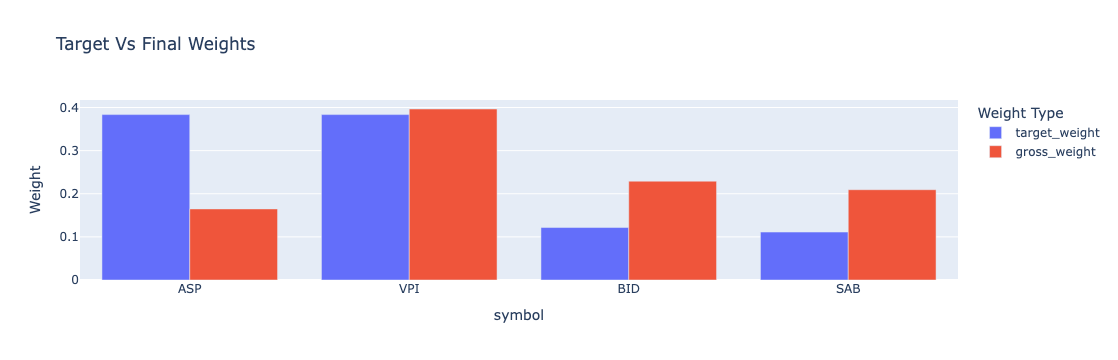

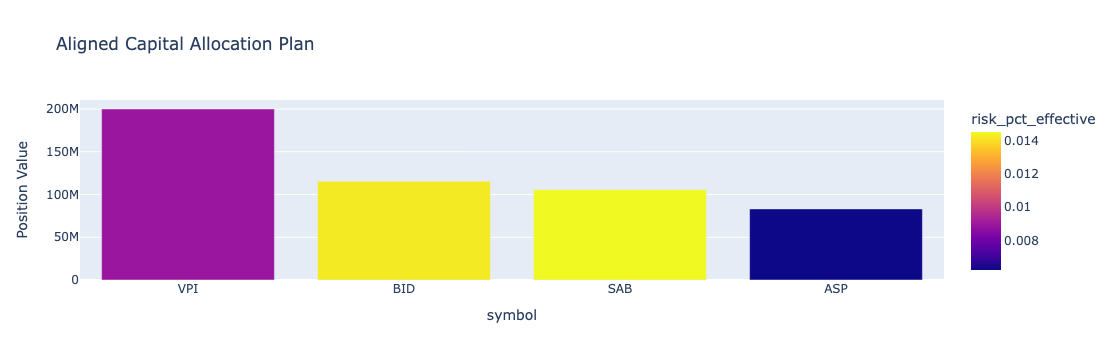

In [8]:
# Cell: Visualize Capital Plan
display(weight_comparison_chart(aligned_plan, title="Target Vs Final Weights"))
capital_plan_chart(aligned_plan, value_col="position_value", title="Aligned Capital Allocation Plan")
